In [1]:
# Author: Om Mohite

import os
from pathlib import Path
from getpass import getpass

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import URL, create_engine, text

# Find and load the existing .env file
env_file = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    candidates = [
        folder / ".env",
        folder / "Data-Engineering-Real-World-Projects" / ".env",
    ]

    for candidate in candidates:
        if candidate.exists():
            env_file = candidate
            break

    if env_file:
        break

if env_file:
    load_dotenv(env_file)

db_password = os.getenv("DB_PASSWORD") or getpass("MySQL password: ")

# Connect to the MySQL server
server_url = URL.create(
    drivername="mysql+pymysql",
    username=os.getenv("DB_USER", "root"),
    password=db_password,
    host=os.getenv("DB_HOST", "localhost"),
    port=int(os.getenv("DB_PORT", "3306")),
)

server_engine = create_engine(server_url, pool_pre_ping=True)

with server_engine.begin() as conn:
    conn.execute(text("CREATE DATABASE IF NOT EXISTS test_case_6"))

# Connect to the Test Case 6 database
engine = create_engine(
    server_url.set(database="test_case_6"),
    pool_pre_ping=True,
)

create_table_sql = """
CREATE TABLE IF NOT EXISTS sales (
    sale_id INT PRIMARY KEY,
    sale_date DATE NOT NULL,
    region VARCHAR(50),
    category VARCHAR(50),
    revenue DECIMAL(10, 2) NOT NULL
)
"""

with engine.begin() as conn:
    conn.execute(text(create_table_sql))
    tables = conn.execute(text("SHOW TABLES")).all()

print("Connected database: test_case_6")
print("Tables:", tables)

server_engine.dispose()

Connected database: test_case_6
Tables: [('sales',)]


In [2]:
# Author: Om Mohite

import re
from pathlib import Path
from sqlalchemy import text

sql_candidates = [
    Path.cwd() / "test_case_6.sql",
    Path.cwd() / "Data-Engineering-Real-World-Projects" / "Test_Case_6" / "test_case_6.sql",
]

sql_file = next((path for path in sql_candidates if path.exists()), None)

if sql_file is None:
    raise FileNotFoundError("Could not find test_case_6.sql.")

sql_script = sql_file.read_text(encoding="utf-8")

insert_statements = [
    statement.strip()
    for statement in sql_script.split(";")
    if re.match(r"\s*INSERT\s+INTO\s+sales\b", statement, re.IGNORECASE)
]

if not insert_statements:
    raise ValueError("No INSERT statement for sales was found.")

with engine.begin() as conn:
    conn.execute(text("TRUNCATE TABLE sales"))

    for statement in insert_statements:
        conn.exec_driver_sql(statement)

with engine.connect() as conn:
    row_count = conn.execute(
        text("SELECT COUNT(*) FROM sales")
    ).scalar_one()

    preview = pd.read_sql(
        "SELECT * FROM sales ORDER BY sale_date, sale_id LIMIT 5",
        con=conn,
    )

print("Rows loaded:", row_count)
display(preview)

if row_count != 24:
    raise ValueError(f"Expected 24 rows; found {row_count}.")

Rows loaded: 24


,sale_id,sale_date,region,category,revenue
0,7,2024-01-10,South,Electronics,9500.0
1,1,2024-01-15,North,Electronics,12000.0
2,2,2024-02-18,North,Electronics,13500.0
3,8,2024-02-22,South,Electronics,10200.0
4,9,2024-03-19,South,Electronics,11800.0


In [3]:
# Author: Om Mohite

def data_extraction(engine):
    extracted_df = pd.read_sql(
        "SELECT * FROM sales",
        con=engine,
    )

    if extracted_df.empty:
        raise ValueError("The sales table contains no records.")

    return extracted_df


def data_transformation(source_df):
    transformed_df = source_df.copy()

    transformed_df = transformed_df[
        transformed_df["sale_date"].notna()
        & transformed_df["sale_id"].notna()
    ].copy()

    if transformed_df["region"].isna().any():
        region_mode = transformed_df["region"].mode()
        if not region_mode.empty:
            transformed_df["region"] = transformed_df["region"].fillna(region_mode.iloc[0])

    if transformed_df["category"].isna().any():
        category_mode = transformed_df["category"].mode()
        if not category_mode.empty:
            transformed_df["category"] = transformed_df["category"].fillna(category_mode.iloc[0])

    transformed_df["revenue"] = pd.to_numeric(
        transformed_df["revenue"],
        errors="coerce",
    )

    transformed_df["revenue"] = transformed_df["revenue"].fillna(
        transformed_df["revenue"].mean()
    )

    transformed_df["sale_date"] = pd.to_datetime(
        transformed_df["sale_date"],
        errors="raise",
    )

    transformed_df["Day"] = transformed_df["sale_date"].dt.day
    transformed_df["Month"] = transformed_df["sale_date"].dt.month
    transformed_df["Year"] = transformed_df["sale_date"].dt.year

    return transformed_df.reset_index(drop=True)


ext_df = data_extraction(engine)
df = data_transformation(ext_df)

print("Extracted rows:", len(ext_df))
print("Transformed rows:", len(df))
display(df.head())

Extracted rows: 24
Transformed rows: 24


,sale_id,sale_date,region,category,revenue,Day,Month,Year
0,1,2024-01-15,North,Electronics,12000.0,15,1,2024
1,2,2024-02-18,North,Electronics,13500.0,18,2,2024
2,3,2024-03-20,North,Electronics,11000.0,20,3,2024
3,4,2024-04-12,North,Electronics,15000.0,12,4,2024
4,5,2024-05-25,North,Electronics,16500.0,25,5,2024


In [4]:
# Author: Om Mohite

monthly_sales = pd.read_sql(
    text("""
        WITH monthly_revenue AS (
            SELECT
                YEAR(sale_date) AS Year,
                MONTH(sale_date) AS Month,
                SUM(revenue) AS monthly_revenue
            FROM sales
            GROUP BY YEAR(sale_date), MONTH(sale_date)
        ),
        revenue_with_previous AS (
            SELECT
                Year,
                Month,
                monthly_revenue,
                LAG(monthly_revenue) OVER (
                    ORDER BY Year, Month
                ) AS previous_month_revenue
            FROM monthly_revenue
        )
        SELECT
            Year,
            Month,
            CONCAT(Year, '-', LPAD(Month, 2, '0')) AS Period,
            monthly_revenue,
            previous_month_revenue,
            ROUND(
                (monthly_revenue - previous_month_revenue)
                * 100.0 / NULLIF(previous_month_revenue, 0),
                2
            ) AS mom_growth_percent
        FROM revenue_with_previous
        ORDER BY Year, Month
    """),
    con=engine,
)

display(monthly_sales)

,Year,Month,Period,monthly_revenue,previous_month_revenue,mom_growth_percent
0,2024,1,2024-01,21500.0,NaN,NaN
1,2024,2,2024-02,23700.0,21500.0,10.23
2,2024,3,2024-03,22800.0,23700.0,-3.80
3,2024,4,2024-04,26200.0,22800.0,14.91
4,2024,5,2024-05,29500.0,26200.0,12.60
5,2024,6,2024-06,32500.0,29500.0,10.17
6,2025,1,2025-01,24850.0,32500.0,-23.54
7,2025,2,2025-02,26500.0,24850.0,6.64
8,2025,3,2025-03,28200.0,26500.0,6.42
9,2025,4,2025-04,29200.0,28200.0,3.55


In [5]:
# Author: Om Mohite
#Year-over-year comparison
yoy_sales = pd.read_sql(
    text("""
        WITH monthly_revenue AS (
            SELECT
                YEAR(sale_date) AS Year,
                MONTH(sale_date) AS Month,
                SUM(revenue) AS monthly_revenue
            FROM sales
            GROUP BY YEAR(sale_date), MONTH(sale_date)
        ),
        revenue_with_previous_year AS (
            SELECT
                Year,
                Month,
                monthly_revenue,
                LAG(monthly_revenue) OVER (
                    PARTITION BY Month
                    ORDER BY Year
                ) AS previous_year_revenue
            FROM monthly_revenue
        )
        SELECT
            Year,
            Month,
            monthly_revenue,
            previous_year_revenue,
            ROUND(
                (monthly_revenue - previous_year_revenue)
                * 100.0 / NULLIF(previous_year_revenue, 0),
                2
            ) AS yoy_growth_percent
        FROM revenue_with_previous_year
        ORDER BY Year, Month
    """),
    con=engine,
)

display(yoy_sales)

,Year,Month,monthly_revenue,previous_year_revenue,yoy_growth_percent
0,2024,1,21500.0,NaN,NaN
1,2024,2,23700.0,NaN,NaN
2,2024,3,22800.0,NaN,NaN
3,2024,4,26200.0,NaN,NaN
4,2024,5,29500.0,NaN,NaN
5,2024,6,32500.0,NaN,NaN
6,2025,1,24850.0,21500.0,15.58
7,2025,2,26500.0,23700.0,11.81
8,2025,3,28200.0,22800.0,23.68
9,2025,4,29200.0,26200.0,11.45


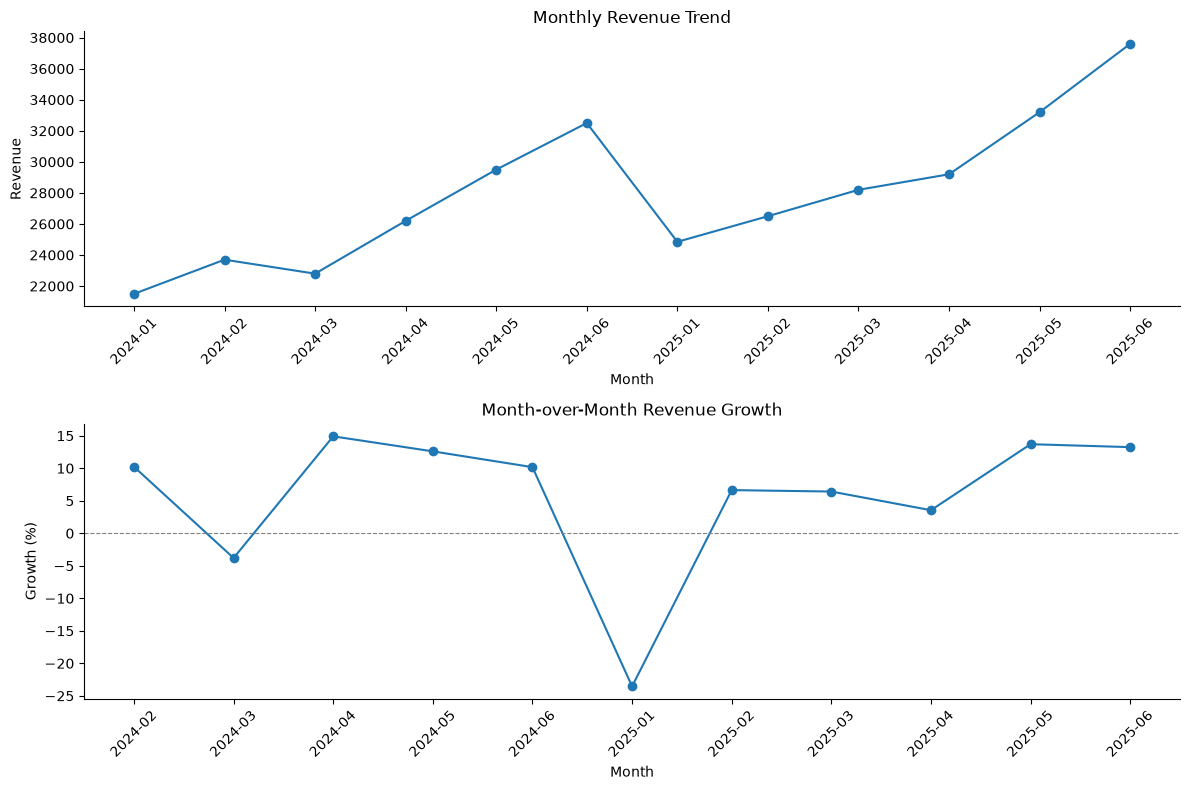

In [6]:
# Author: Om Mohite
#Monthly revenue आणि MoM growth charts
import matplotlib.pyplot as plt

monthly_sales["Period"] = (
    monthly_sales["Year"].astype(str)
    + "-"
    + monthly_sales["Month"].astype(str).str.zfill(2)
)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(
    monthly_sales["Period"],
    monthly_sales["monthly_revenue"],
    marker="o",
)
axes[0].set_title("Monthly Revenue Trend")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue")
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(
    monthly_sales["Period"],
    monthly_sales["mom_growth_percent"],
    marker="o",
)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].set_title("Month-over-Month Revenue Growth")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Growth (%)")
axes[1].tick_params(axis="x", rotation=45)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [7]:
# Author: Om Mohite
# Keep MoM comparisons only when the months are consecutive


period_number = monthly_sales["Year"] * 12 + monthly_sales["Month"]
has_previous_calendar_month = period_number.diff().eq(1)

monthly_sales.loc[
    ~has_previous_calendar_month,
    ["previous_month_revenue", "mom_growth_percent"],
] = pd.NA

expected_monthly_revenue = {
    (2024, 1): 21500.0,
    (2024, 2): 23700.0,
    (2024, 3): 22800.0,
    (2024, 4): 26200.0,
    (2024, 5): 29500.0,
    (2024, 6): 32500.0,
    (2025, 1): 24850.0,
    (2025, 2): 26500.0,
    (2025, 3): 28200.0,
    (2025, 4): 29200.0,
    (2025, 5): 33200.0,
    (2025, 6): 37600.0,
}

actual_monthly_revenue = {
    (int(row.Year), int(row.Month)): float(row.monthly_revenue)
    for row in monthly_sales.itertuples()
}

if actual_monthly_revenue != expected_monthly_revenue:
    raise AssertionError(
        f"Monthly revenue totals do not match: {actual_monthly_revenue}"
    )

print("TEST CASE 6 VALIDATION PASSED")
print("Monthly revenue totals match the source SQL data.")
display(monthly_sales)

TEST CASE 6 VALIDATION PASSED
Monthly revenue totals match the source SQL data.


,Year,Month,Period,monthly_revenue,previous_month_revenue,mom_growth_percent
0,2024,1,2024-01,21500.0,NaN,NaN
1,2024,2,2024-02,23700.0,21500.0,10.23
2,2024,3,2024-03,22800.0,23700.0,-3.80
3,2024,4,2024-04,26200.0,22800.0,14.91
4,2024,5,2024-05,29500.0,26200.0,12.60
5,2024,6,2024-06,32500.0,29500.0,10.17
6,2025,1,2025-01,24850.0,NaN,NaN
7,2025,2,2025-02,26500.0,24850.0,6.64
8,2025,3,2025-03,28200.0,26500.0,6.42
9,2025,4,2025-04,29200.0,28200.0,3.55
